In [48]:
# Pulsar candidate classification (HTRU2)

#Goal: classify radio-signal candidates as real pulsars (1) or noise/interference (0).
#This notebook covers data checks, EDA, feature importance and model selection.

In [49]:
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [50]:
df = pd.read_csv("data/htru2.csv")
features = [c for c in df.columns if c != "class"]

print("Shape:", df.shape)
print("Missing values per column:\n", df.isna().sum())
print("Duplicated rows:", df.duplicated().sum())
df.describe().T

Shape: (17898, 9)
Missing values per column:
 Profile_mean        0
Profile_stdev       0
Profile_skewness    0
Profile_kurtosis    0
DM_mean             0
DM_stdev            0
DM_skewness         0
DM_kurtosis         0
class               0
dtype: int64
Duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
Profile_mean,17898.0,111.079968,25.652935,5.812500,100.929688,115.078125,127.085938,192.617188
Profile_stdev,17898.0,46.549532,6.843189,24.772042,42.376018,46.947479,51.023202,98.778911
Profile_skewness,17898.0,0.477857,1.064040,-1.876011,0.027098,0.223240,0.473325,8.069522
Profile_kurtosis,17898.0,1.770279,6.167913,-1.791886,-0.188572,0.198710,0.927783,68.101622
DM_mean,17898.0,12.614400,29.472897,0.213211,1.923077,2.801839,5.464256,223.392141
DM_stdev,17898.0,26.326515,19.470572,7.370432,14.437332,18.461316,28.428104,110.642211
DM_skewness,17898.0,8.303556,4.506092,-3.139270,5.781506,8.433515,10.702959,34.539844
DM_kurtosis,17898.0,104.857709,106.514540,-1.976976,34.960504,83.064556,139.309330,1191.000837
class,17898.0,0.091574,0.288432,0.000000,0.000000,0.000000,0.000000,1.000000


In [51]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, stratify=df["class"], random_state=RANDOM_STATE
)
print(df_full_train.shape, df_test.shape)
print("Pulsar rate (train / test):",
      round(df_full_train["class"].mean(), 4), round(df_test["class"].mean(), 4))

(14318, 9) (3580, 9)
Pulsar rate (train / test): 0.0916 0.0916


class
0    13007
1     1311
Name: count, dtype: int64
class
0    90.84
1     9.16
Name: count, dtype: float64


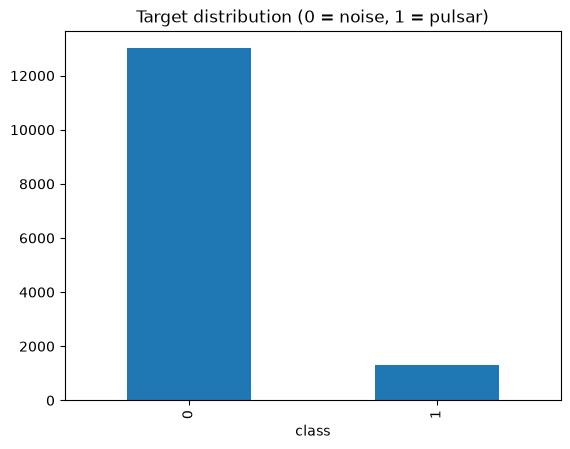

In [52]:
counts = df_full_train["class"].value_counts()
print(counts)
print((counts / len(df_full_train) * 100).round(2))

counts.plot(kind="bar", title="Target distribution (0 = noise, 1 = pulsar)")
plt.show()

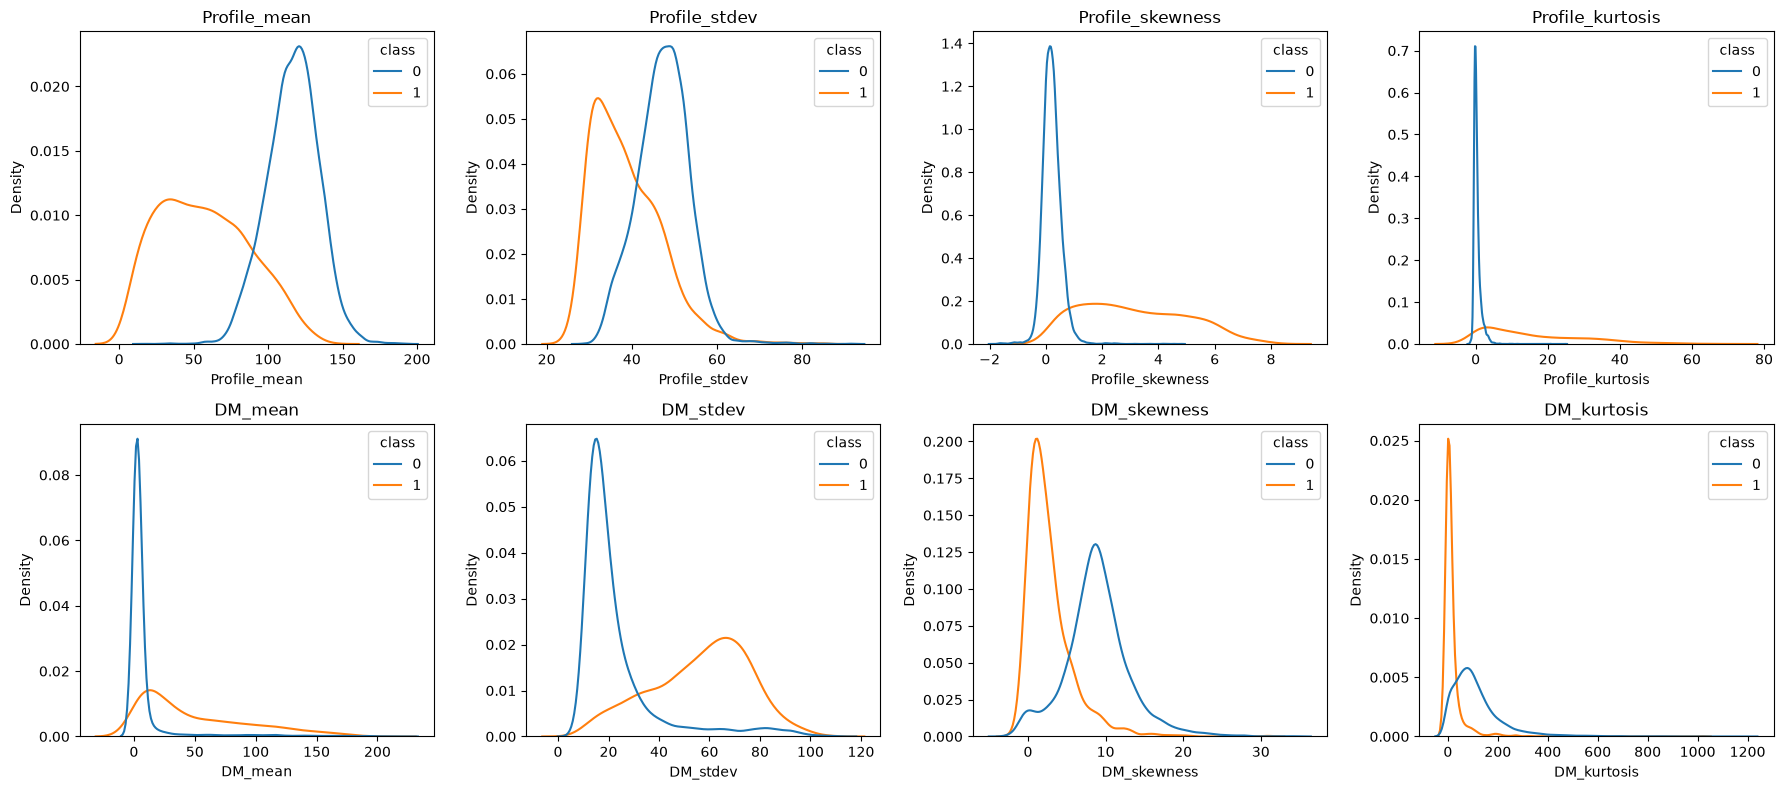

In [53]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), features):
    sns.kdeplot(data=df_full_train, x=col, hue="class", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [54]:
df_full_train.groupby("class")[features].mean().T

class,0,1
Profile_mean,116.485394,57.203435
Profile_stdev,47.298525,38.740470
Profile_skewness,0.212146,3.116215
Profile_kurtosis,0.387841,15.506967
DM_mean,8.671204,49.008417
DM_stdev,23.199585,56.384276
DM_skewness,8.892920,2.740716
DM_kurtosis,114.283793,17.112487


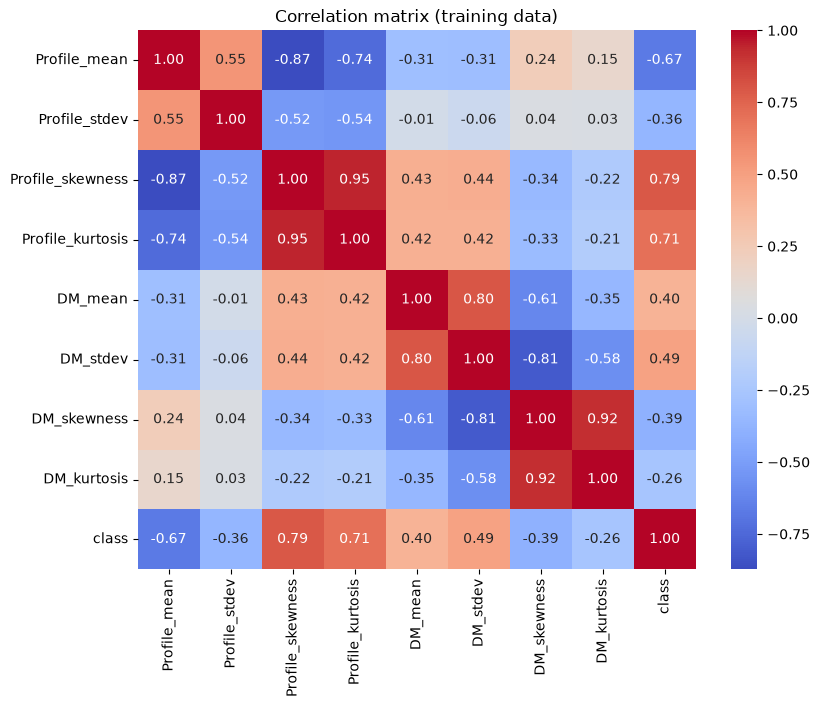

In [55]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_full_train.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix (training data)")
plt.show()

,mutual_info,rf_importance
Profile_skewness,0.225570,0.323271
Profile_mean,0.187689,0.170556
Profile_kurtosis,0.191196,0.166953
DM_stdev,0.119853,0.113621
DM_mean,0.116339,0.079995
DM_kurtosis,0.119130,0.065664
DM_skewness,0.114933,0.045568
Profile_stdev,0.088040,0.034373


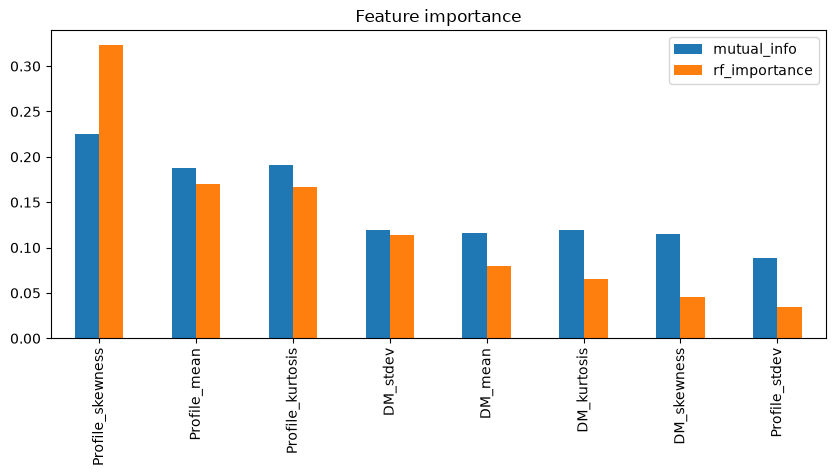

In [56]:
X = df_full_train[features]
y = df_full_train["class"]

mi = pd.Series(mutual_info_classif(X, y, random_state=RANDOM_STATE), index=features)
rf = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
).fit(X, y)
rf_imp = pd.Series(rf.feature_importances_, index=features)

importance = pd.DataFrame({"mutual_info": mi, "rf_importance": rf_imp})
importance = importance.sort_values("rf_importance", ascending=False)
display(importance)
importance.plot(kind="bar", figsize=(10, 4), title="Feature importance")
plt.show()

In [57]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

In [58]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": "f1",
    "recall": "recall",
    "precision": "precision",
}

neg, pos = (y == 0).sum(), (y == 1).sum()

models = {
    "logistic_regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")
    ),
    "random_forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
    "xgboost": XGBClassifier(
        n_estimators=300, scale_pos_weight=neg / pos, eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=-1,
    ),
}

rows = []
for name, model in models.items():
    res = cross_validate(model, X, y, cv=cv, scoring=scoring)
    row = {"model": name}
    for m in scoring:
        row[m] = f"{res[f'test_{m}'].mean():.4f} ± {res[f'test_{m}'].std():.4f}"
    rows.append(row)

pd.DataFrame(rows)

,model,pr_auc,roc_auc,f1,recall,precision
0,logistic_regression,0.9229 ± 0.0124,0.9770 ± 0.0040,0.8421 ± 0.0125,0.9116 ± 0.0305,0.7832 ± 0.0177
1,random_forest,0.9232 ± 0.0162,0.9735 ± 0.0062,0.8804 ± 0.0170,0.8757 ± 0.0334,0.8861 ± 0.0127
2,xgboost,0.9202 ± 0.0181,0.9721 ± 0.0088,0.8765 ± 0.0184,0.8650 ± 0.0280,0.8886 ± 0.0113


In [59]:
from sklearn.dummy import DummyClassifier

dummy = cross_validate(
    DummyClassifier(strategy="prior"), X, y, cv=cv,
    scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
)
print("Baseline PR-AUC:", dummy["test_pr_auc"].mean().round(4))
print("Baseline ROC-AUC:", dummy["test_roc_auc"].mean().round(4))

Baseline PR-AUC: 0.0916
Baseline ROC-AUC: 0.5


In [60]:
## Hyperparameter tuning

In [61]:
searches = {
    "logistic_regression": GridSearchCV(
        make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000, class_weight="balanced"),
        ),
        {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
        scoring="average_precision", cv=cv, n_jobs=-1,
    ),
    "random_forest": RandomizedSearchCV(
        RandomForestClassifier(
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1
        ),
        {
            "n_estimators": [200, 400],
            "max_depth": [None, 8, 16],
            "min_samples_leaf": [1, 3, 5],
            "max_features": ["sqrt", 0.5],
        },
        n_iter=15, scoring="average_precision", cv=cv, n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "xgboost": RandomizedSearchCV(
        XGBClassifier(
            scale_pos_weight=neg / pos, eval_metric="logloss",
            random_state=RANDOM_STATE, n_jobs=1,
        ),
        {
            "n_estimators": [200, 400],
            "max_depth": [3, 5, 7],
            "learning_rate": [0.03, 0.1, 0.3],
            "subsample": [0.8, 1.0],
            "colsample_bytree": [0.8, 1.0],
        },
        n_iter=20, scoring="average_precision", cv=cv, n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}

tuned, rows = {}, []
for name, search in searches.items():
    search.fit(X, y)
    tuned[name] = search.best_estimator_
    rows.append({
        "model": name,
        "best_cv_pr_auc": round(search.best_score_, 4),
        "best_params": search.best_params_,
    })

tuning_results = pd.DataFrame(rows).sort_values("best_cv_pr_auc", ascending=False)
pd.set_option("display.max_colwidth", None)
tuning_results

,model,best_cv_pr_auc,best_params
2,xgboost,0.9307,"{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.8}"
1,random_forest,0.9296,"{'n_estimators': 400, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8}"
0,logistic_regression,0.9240,{'logisticregression__C': 0.1}


In [ ]:
**Tuning results**
- Tuning improves all models slightly (PR-AUC: XGBoost 0.931, random forest 0.930, logistic regression 0.924).
- Differences between the best models are within the fold-to-fold variation, so the choice is not decisive. XGBoost is selected as the best by cross-validated PR-AUC.
- The reported scores are optimistic because the best configuration was chosen on the same folds; the final estimate comes from the held-out test set.
- Some best values lie on the edge of the search grid, so a wider search could give small further gains.

In [ ]:
for name, search in searches.items():
    i = search.best_index_
    mean = search.cv_results_["mean_test_score"][i]
    std = search.cv_results_["std_test_score"][i]
    print(f"{name}: {mean:.4f} ± {std:.4f}")

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

best_model = tuned["xgboost"]
proba_cv = cross_val_predict(best_model, X, y, cv=cv, method="predict_proba")[:, 1]

precision, recall, thresholds = precision_recall_curve(y, proba_cv)
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)

i_f1 = f1.argmax()
print(f"Max F1: threshold {thresholds[i_f1]:.3f}, precision {precision[i_f1]:.3f}, recall {recall[i_f1]:.3f}")

i_rec = np.where(recall[:-1] >= 0.90)[0].max()
print(f"Recall >= 0.90: threshold {thresholds[i_rec]:.3f}, precision {precision[i_rec]:.3f}, recall {recall[i_rec]:.3f}")

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = proba_cv >= t
    tp = (pred & (y == 1)).sum()
    print(f"t={t}: precision {tp / max(pred.sum(), 1):.3f}, recall {tp / (y == 1).sum():.3f}")